# Telco Customer Churn Prediction

Predicting which customers will leave a telecom provider, using a synthetic dataset of 100,000 customers.

**Workflow:** load data → quality checks → cleaning → exploratory analysis →  train/test split → logistic regression (baseline) → Random Forest → model comparison → conclusions.

**Data:** place `C:\Users\user\Desktop\Telco-Cust-Churn\synthetic_customer_churn_100k.csv` in the `data/` folder (see the project README for the source).

## 1. Setup

In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
RANDOM_STATE = 42

## 2. Load Data

In [19]:
DATA_PATH = r"C:\Users\user\Desktop\Telco-Cust-Churn\synthetic_customer_churn_100k.csv"
df = pd.read_csv(r"C:\Users\user\Desktop\Telco-Cust-Churn\data\synthetic_customer_churn_100k.csv")
print("Shape:", df.shape)
df.head()

Shape: (100000, 9)


,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No


## 3. Data Quality Checks

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   CustomerID      100000 non-null  int64  
 1   Age             100000 non-null  int64  
 2   Gender          100000 non-null  str    
 3   Tenure          100000 non-null  int64  
 4   MonthlyCharges  100000 non-null  float64
 5   Contract        100000 non-null  str    
 6   PaymentMethod   100000 non-null  str    
 7   TotalCharges    100000 non-null  float64
 8   Churn           100000 non-null  str    
dtypes: float64(2), int64(3), str(4)
memory usage: 6.9 MB


In [21]:
df.isnull().sum()

CustomerID        0
Age               0
Gender            0
Tenure            0
MonthlyCharges    0
Contract          0
PaymentMethod     0
TotalCharges      0
Churn             0
dtype: int64

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df.describe()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,49.027240,36.527090,79.974933,2926.140256
std,28867.657797,18.177862,20.789552,40.491961,2388.163672
min,1.000000,18.000000,1.000000,10.000000,-118.430000
25%,25000.750000,33.000000,18.000000,44.720000,963.667500
50%,50000.500000,49.000000,37.000000,80.000000,2268.060000
75%,75000.250000,65.000000,54.000000,115.050000,4394.327500
max,100000.000000,80.000000,72.000000,150.000000,10831.460000


**Observations**
- 100,000 rows, 9 columns, no missing values, no duplicate rows.
- `TotalCharges` has a minimum of about -118, which is not possible for real billing data. These rows are removed in the next section.

## 4. Data Cleaning

In [24]:
# Negative TotalCharges are invalid billing values (synthetic-data artefact)
neg_mask = df['TotalCharges'] < 0
print(f"Rows with negative TotalCharges: {neg_mask.sum()} ({neg_mask.mean()*100:.2f}%)")

df = df[~neg_mask].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Rows with negative TotalCharges: 265 (0.27%)
Shape after cleaning: (99735, 9)


No missing values or duplicates were found, so the only cleaning needed is removing the invalid `TotalCharges` rows. Categorical encoding happens in the preprocessing section.

## 5. Exploratory Data Analysis

### Target and numeric distributions

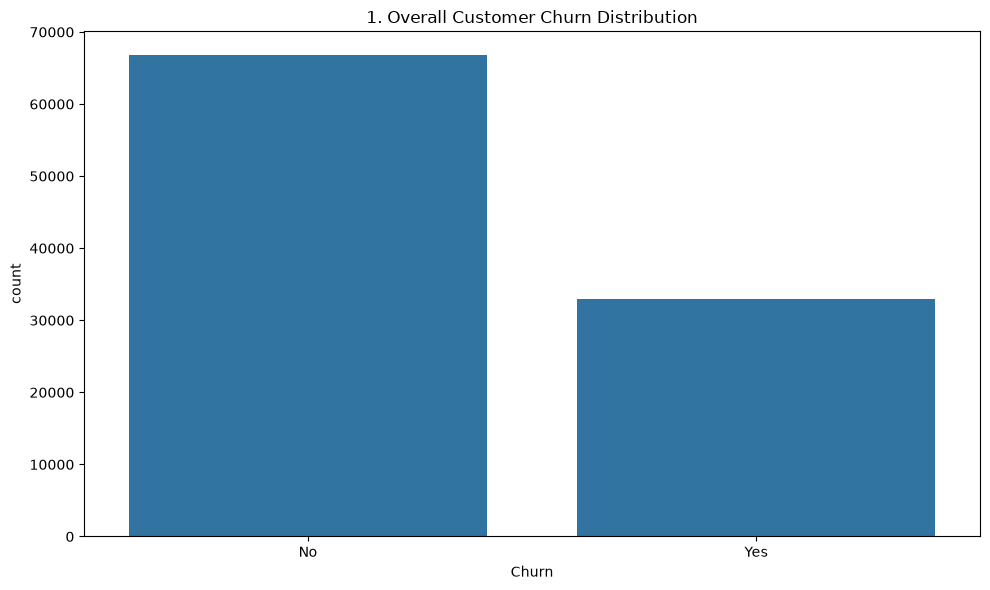

In [25]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Churn')
plt.title('1. Overall Customer Churn Distribution')
plt.tight_layout()
plt.show()

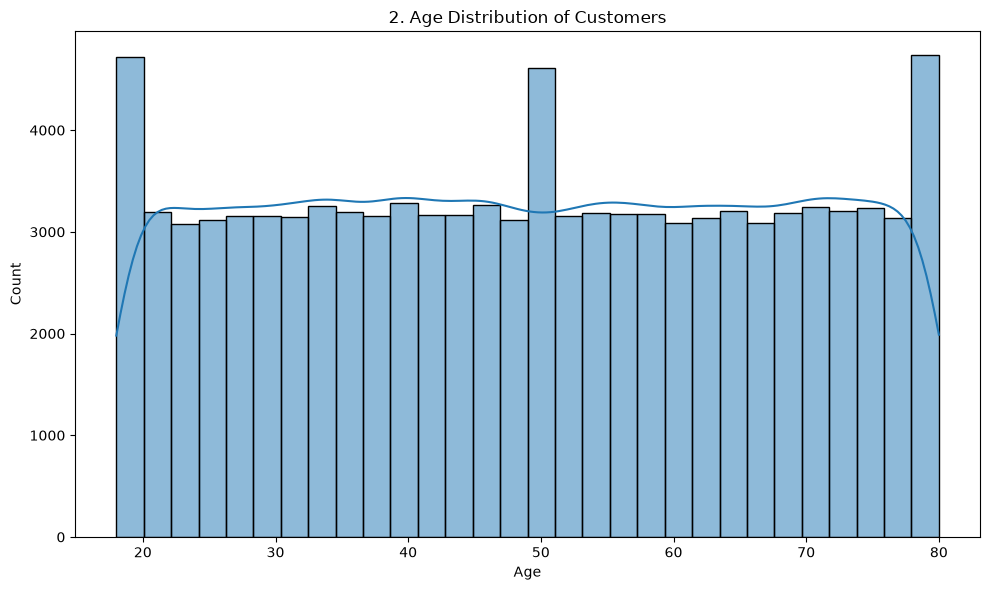

In [26]:
fig = plt.figure(figsize=(10,6))
sns.histplot(df['Age'], bins=30, kde=True)
plt.title('2. Age Distribution of Customers')
plt.tight_layout()
plt.show()

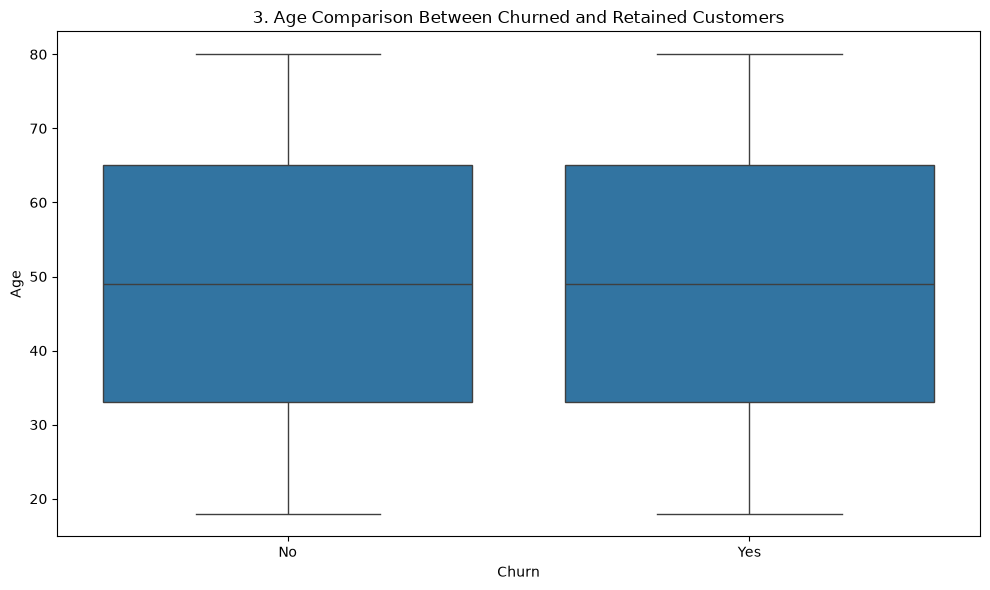

In [27]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Churn', y='Age')
plt.title('3. Age Comparison Between Churned and Retained Customers')
plt.tight_layout()
plt.show()

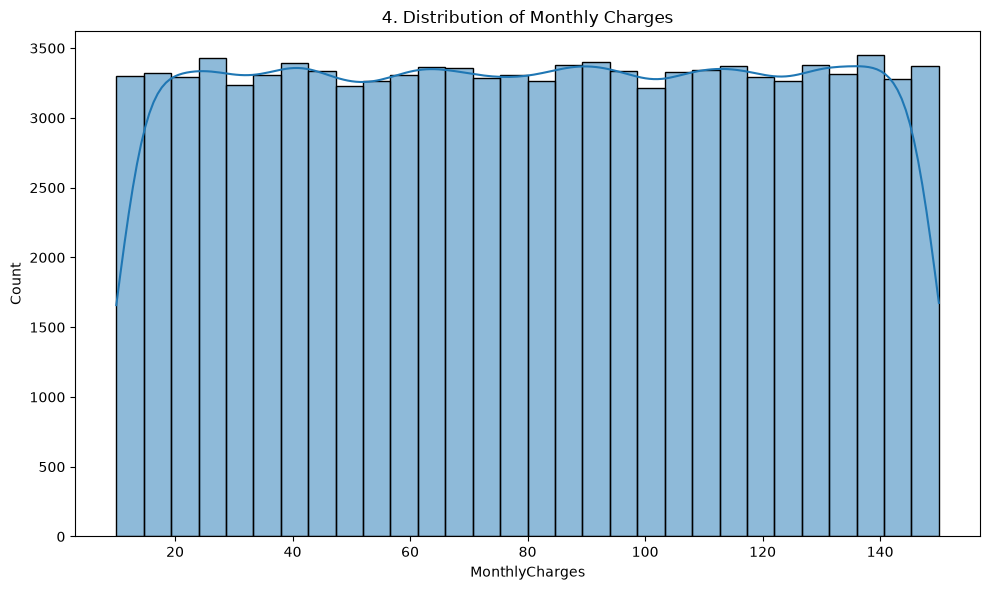

In [28]:
fig = plt.figure(figsize=(10,6))
sns.histplot(df['MonthlyCharges'], bins=30, kde=True)
plt.title('4. Distribution of Monthly Charges')
plt.tight_layout()
plt.show()

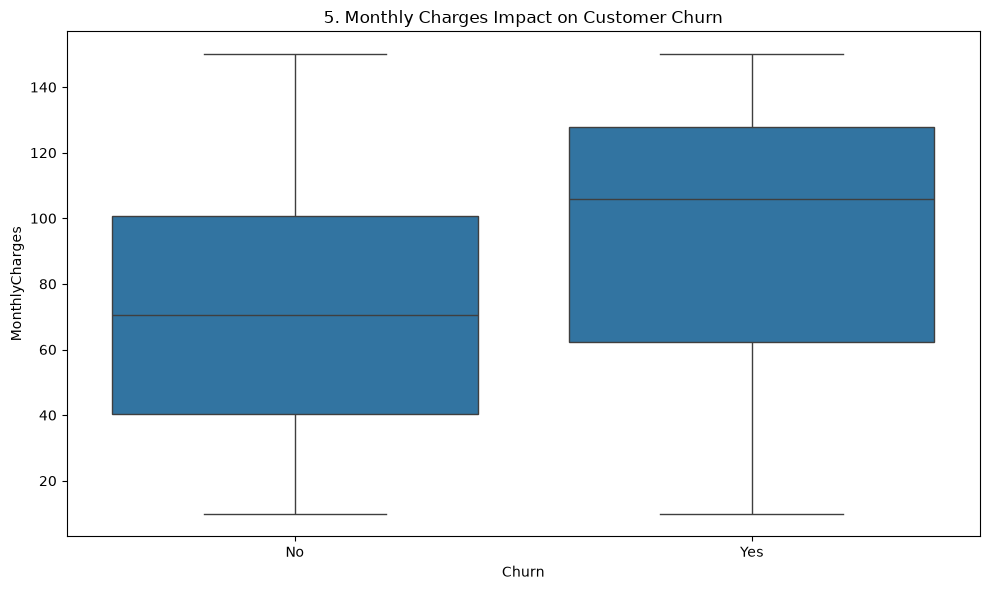

In [29]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('5. Monthly Charges Impact on Customer Churn')
plt.tight_layout()
plt.show()

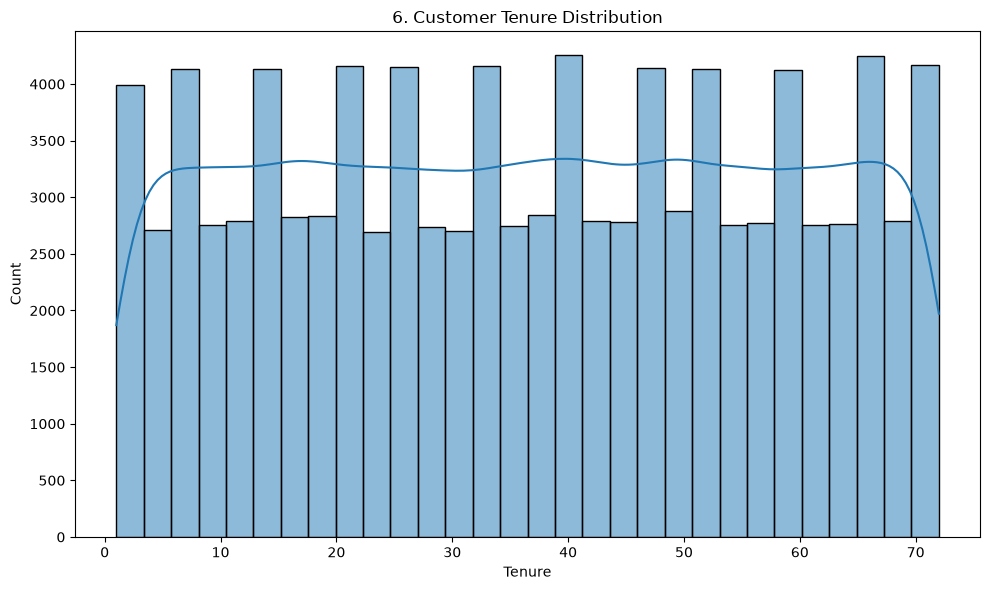

In [30]:
fig = plt.figure(figsize=(10,6))
sns.histplot(df['Tenure'], bins=30, kde=True)
plt.title('6. Customer Tenure Distribution')
plt.tight_layout()
plt.show()

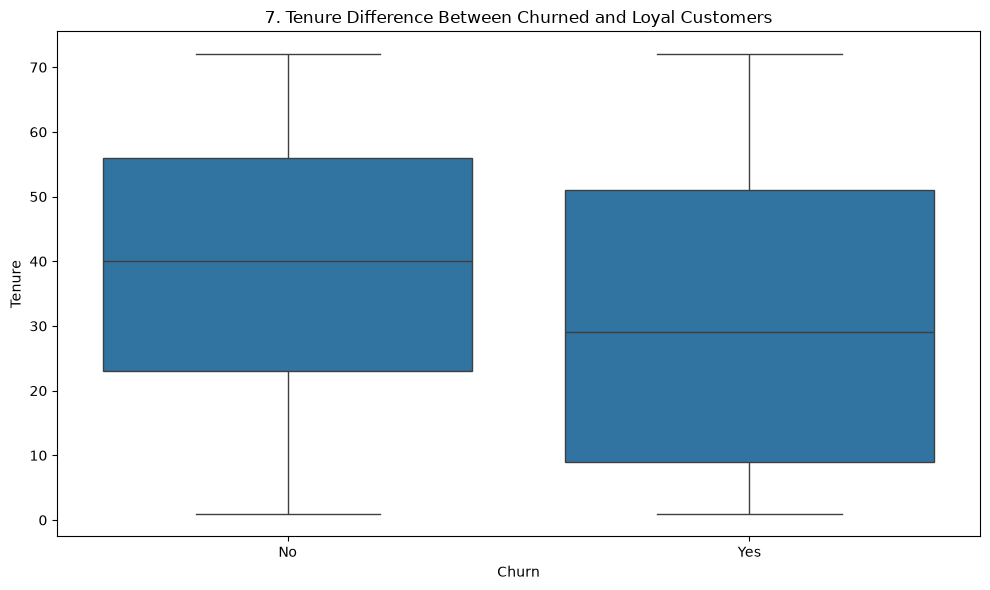

In [31]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Churn', y='Tenure')
plt.title('7. Tenure Difference Between Churned and Loyal Customers')
plt.tight_layout()
plt.show()

### Categorical features vs churn

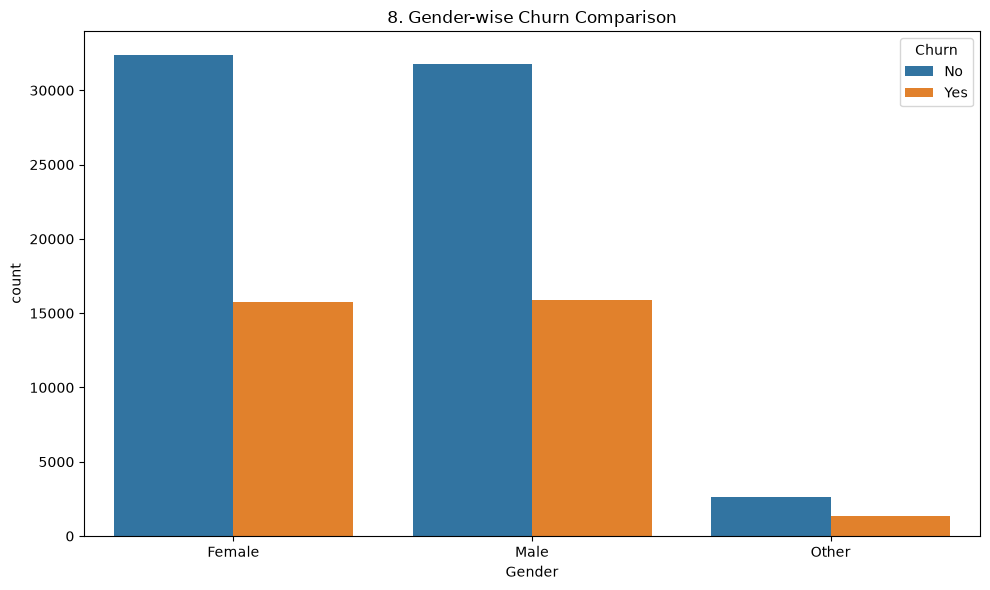

In [32]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Gender', hue='Churn')
plt.title('8. Gender-wise Churn Comparison')
plt.tight_layout()
plt.show()

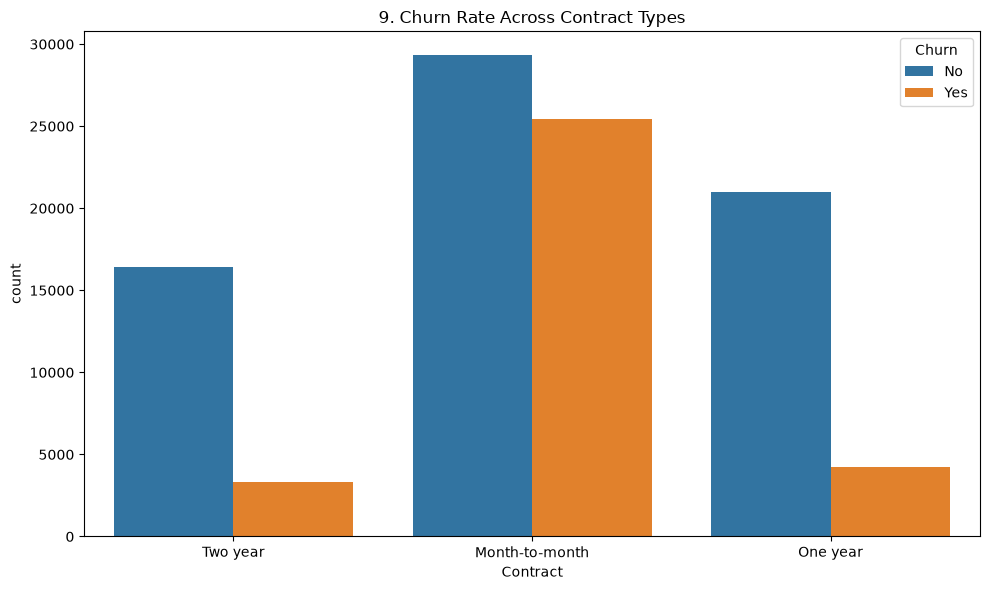

In [33]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('9. Churn Rate Across Contract Types')
plt.tight_layout()
plt.show()

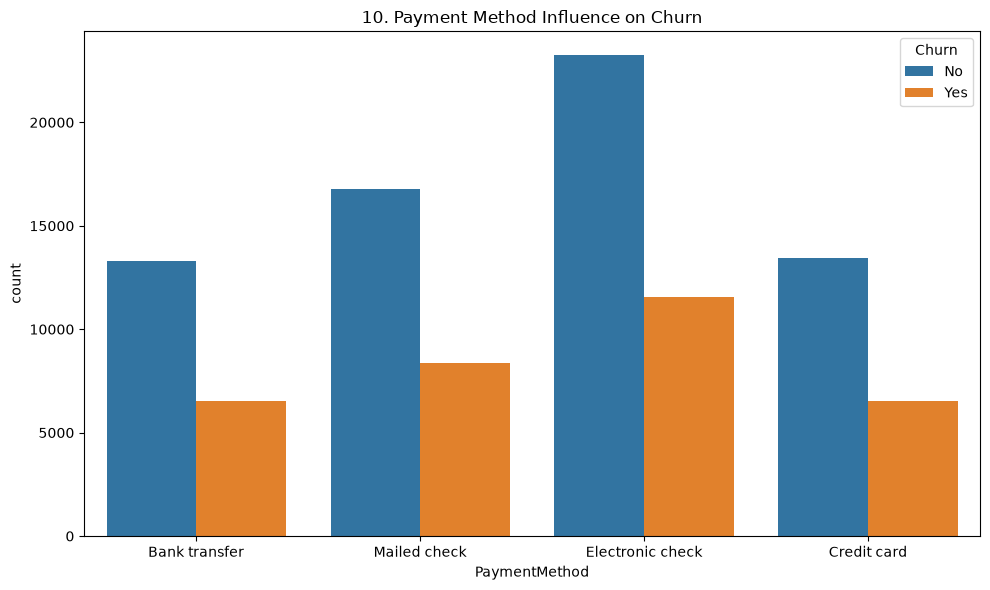

In [34]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='PaymentMethod', hue='Churn')
plt.title('10. Payment Method Influence on Churn')
plt.tight_layout()
plt.show()

### Charges

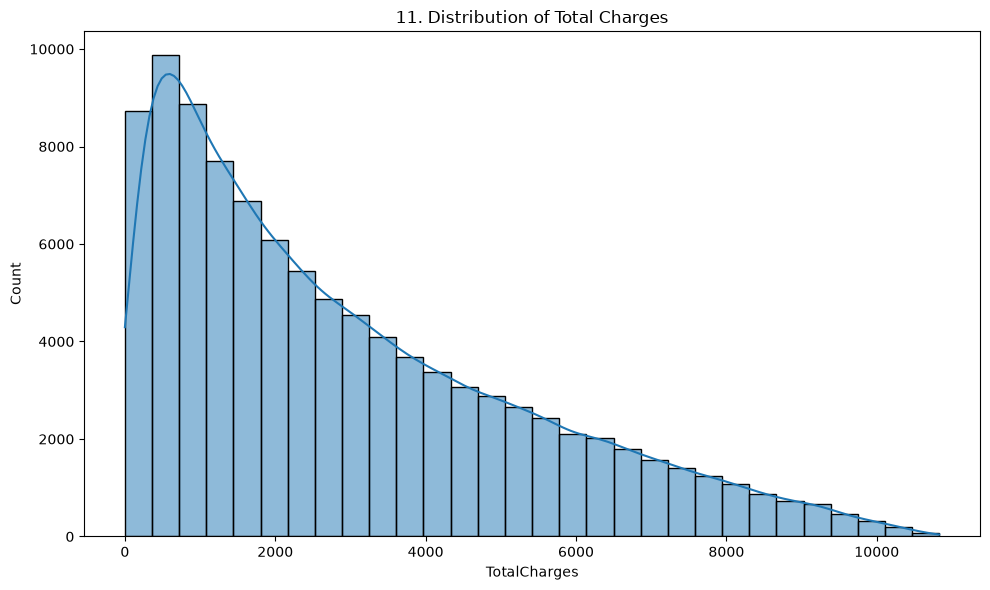

In [35]:
fig = plt.figure(figsize=(10,6))
sns.histplot(df['TotalCharges'], bins=30, kde=True)
plt.title('11. Distribution of Total Charges')
plt.tight_layout()
plt.show()

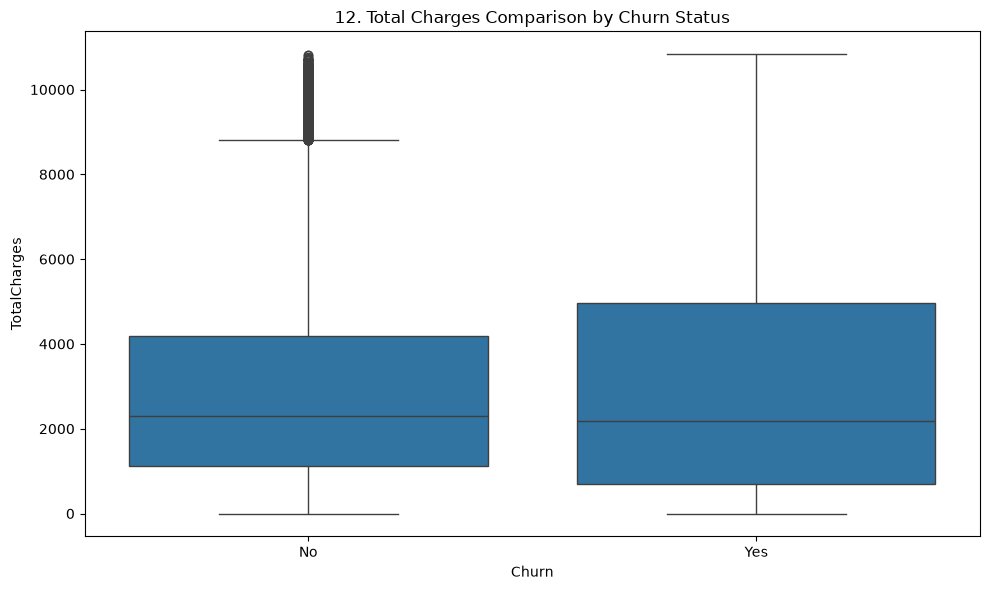

In [36]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Churn', y='TotalCharges')
plt.title('12. Total Charges Comparison by Churn Status')
plt.tight_layout()
plt.show()

### Feature relationships

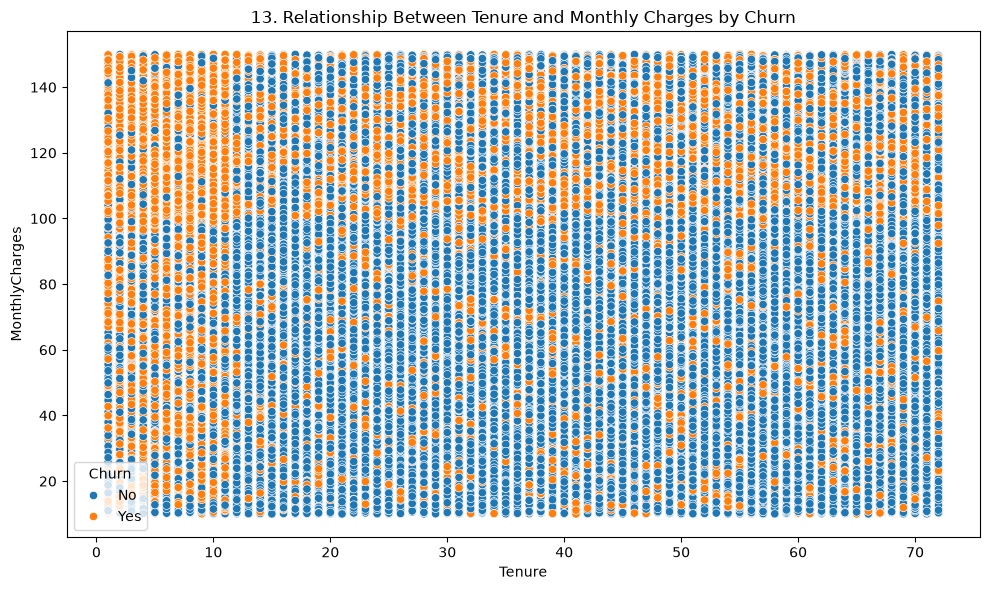

In [37]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Tenure', y='MonthlyCharges', hue='Churn')
plt.title('13. Relationship Between Tenure and Monthly Charges by Churn')
plt.tight_layout()
plt.show()

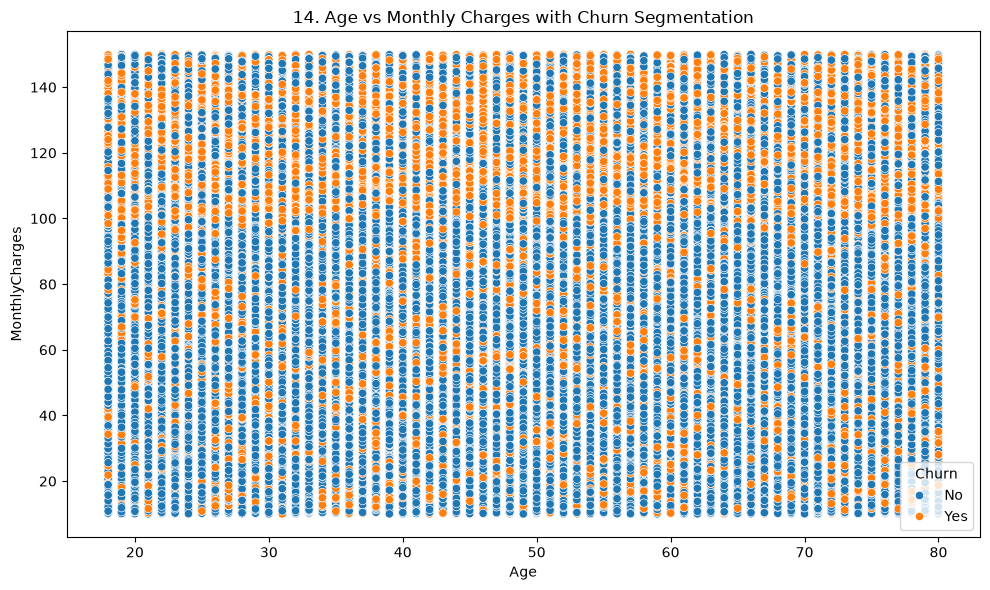

In [38]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Age', y='MonthlyCharges', hue='Churn')
plt.title('14. Age vs Monthly Charges with Churn Segmentation')
plt.tight_layout()
plt.show()

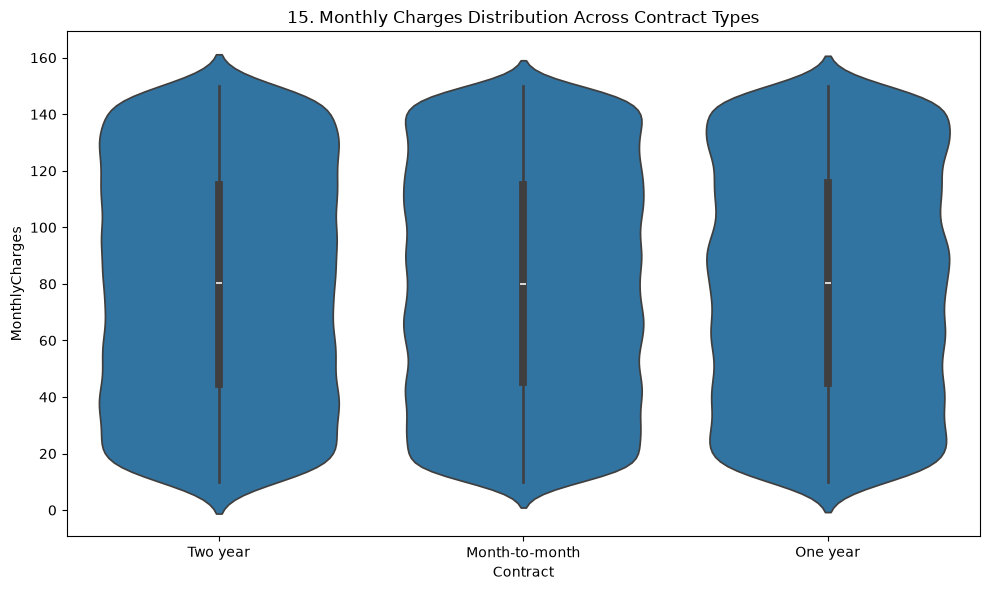

In [39]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='Contract', y='MonthlyCharges')
plt.title('15. Monthly Charges Distribution Across Contract Types')
plt.tight_layout()
plt.show()

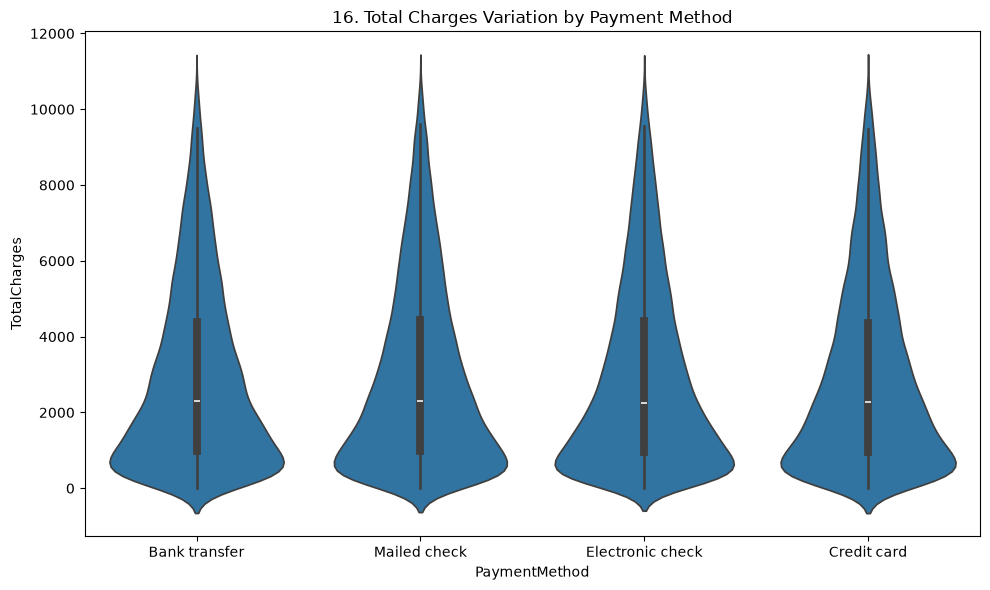

In [40]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='PaymentMethod', y='TotalCharges')
plt.title('16. Total Charges Variation by Payment Method')
plt.tight_layout()
plt.show()

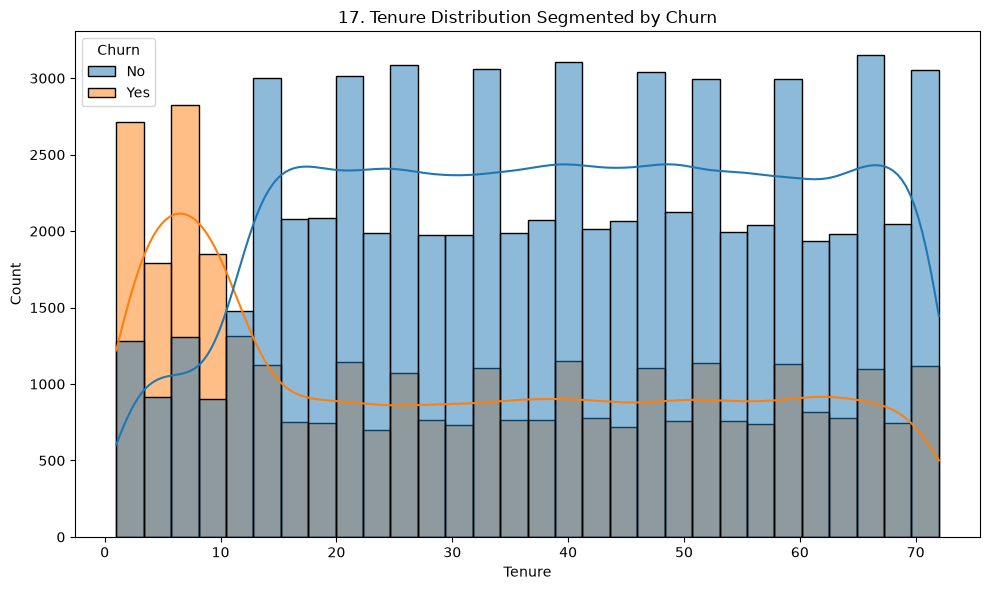

In [41]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Tenure', hue='Churn', bins=30, kde=True)
plt.title('17. Tenure Distribution Segmented by Churn')
plt.tight_layout()
plt.show()

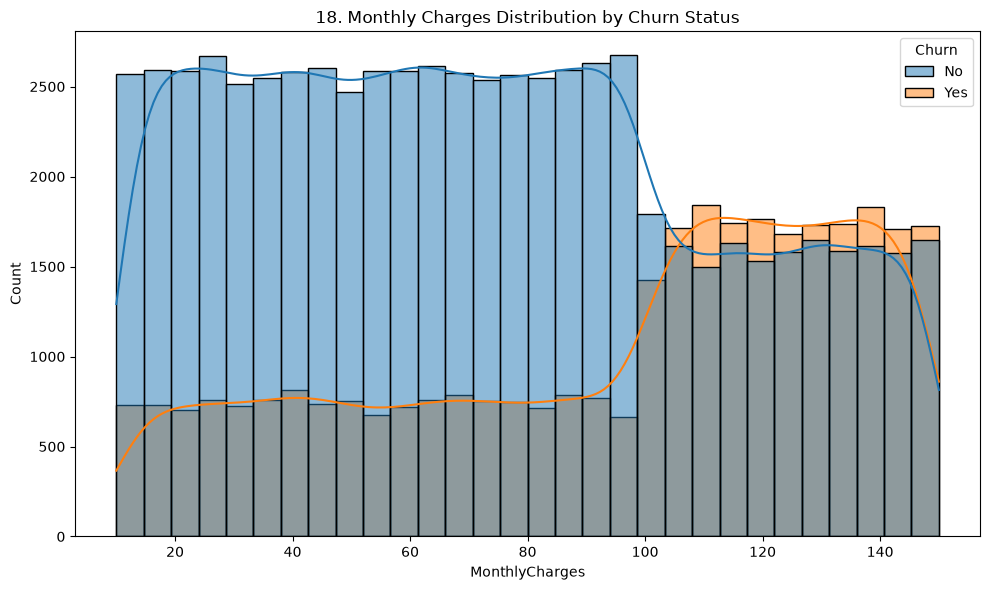

In [42]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30, kde=True)
plt.title('18. Monthly Charges Distribution by Churn Status')
plt.tight_layout()
plt.show()

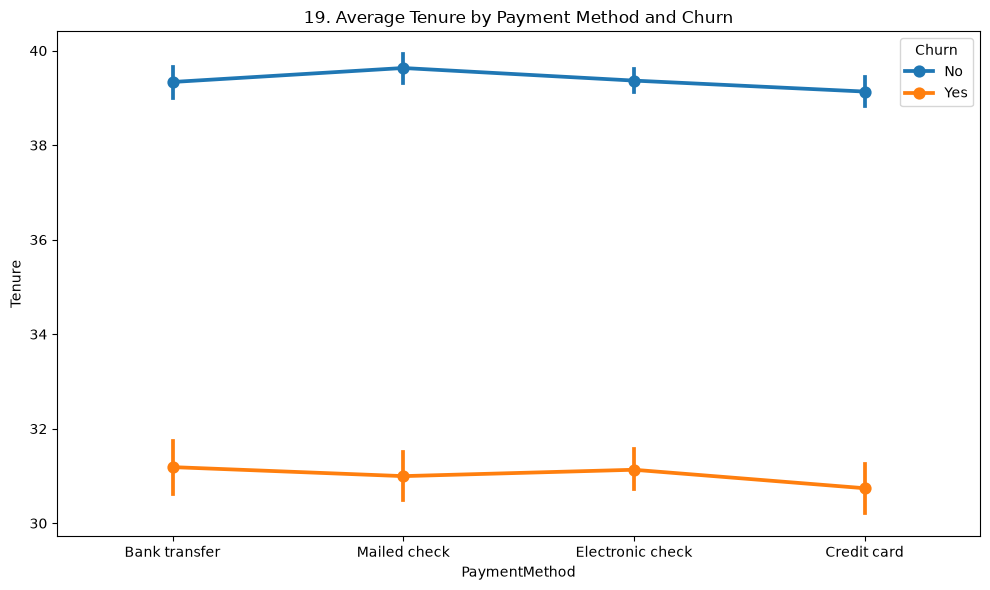

In [43]:
fig = plt.figure(figsize=(10,6))
sns.pointplot(data=df, x='PaymentMethod', y='Tenure', hue='Churn')
plt.title('19. Average Tenure by Payment Method and Churn')
plt.tight_layout()
plt.show()

## 6. Preprocessing and Train/Test/Split

In [44]:
data = df.copy()

# Encode categorical columns (CustomerID is an identifier, dropped below)
categorical_cols = ['Gender', 'Contract', 'PaymentMethod', 'Churn']
for col in categorical_cols:
    data[col] = LabelEncoder().fit_transform(data[col])

X = data.drop(['CustomerID', 'Churn'], axis=1)
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Scaling is needed for Logistic Regression (Random Forest does not need it)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only to avoid leakage
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate (train):", round(y_train.mean(), 3), "| (test):", round(y_test.mean(), 3))

Train: (79788, 7) | Test: (19947, 7)
Churn rate (train): 0.331 | (test): 0.331


## 7. Model 1: Logistic Regression (Baseline)

In [45]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)
log_pred = log_model.predict(X_test_scaled)

## 8. Model 2: Random Forest

In [46]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

## 9. Model Evaluation

In [47]:
baseline = (y_test == 0).mean()
print(f"Majority-class baseline accuracy: {baseline*100:.2f}%\n")

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy':  [accuracy_score(y_test, p)  for p in (log_pred, rf_pred)],
    'Precision': [precision_score(y_test, p) for p in (log_pred, rf_pred)],
    'Recall':    [recall_score(y_test, p)    for p in (log_pred, rf_pred)],
    'F1':        [f1_score(y_test, p)        for p in (log_pred, rf_pred)],
}).round(4)
results

Majority-class baseline accuracy: 66.93%



,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.7268,0.6203,0.4482,0.5204
1,Random Forest,0.7374,0.6290,0.5017,0.5582


In [48]:
print("Logistic Regression\n", classification_report(y_test, log_pred, target_names=['No churn', 'Churn']))
print("Random Forest\n", classification_report(y_test, rf_pred, target_names=['No churn', 'Churn']))

Logistic Regression
               precision    recall  f1-score   support

    No churn       0.76      0.86      0.81     13350
       Churn       0.62      0.45      0.52      6597

    accuracy                           0.73     19947
   macro avg       0.69      0.66      0.66     19947
weighted avg       0.71      0.73      0.71     19947

Random Forest
               precision    recall  f1-score   support

    No churn       0.78      0.85      0.81     13350
       Churn       0.63      0.50      0.56      6597

    accuracy                           0.74     19947
   macro avg       0.70      0.68      0.69     19947
weighted avg       0.73      0.74      0.73     19947



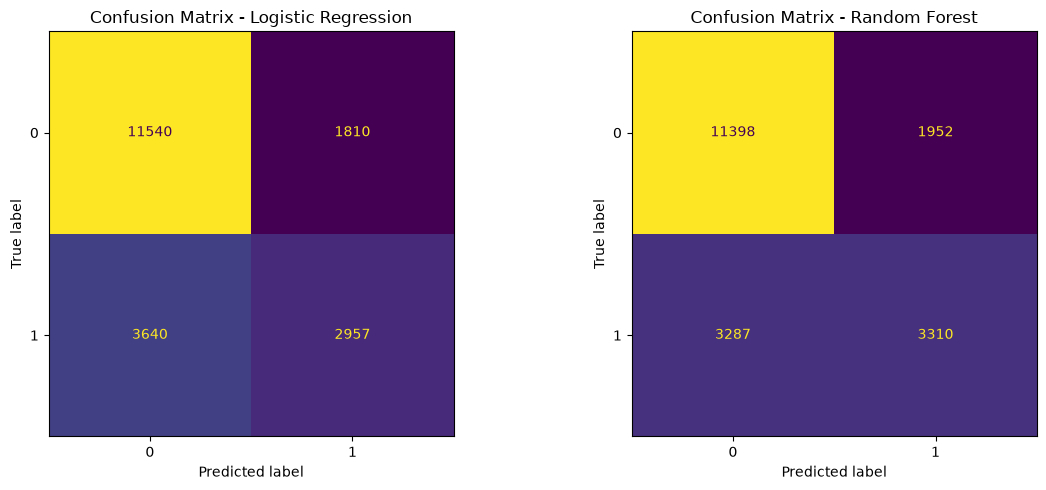

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, pred in zip(axes, ['Logistic Regression', 'Random Forest'], [log_pred, rf_pred]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=ax, colorbar=False)
    ax.set_title(f"Confusion Matrix - {name}")
plt.tight_layout()

os.makedirs("../images", exist_ok=True)
plt.show()

## 10. What Drives Churn ?

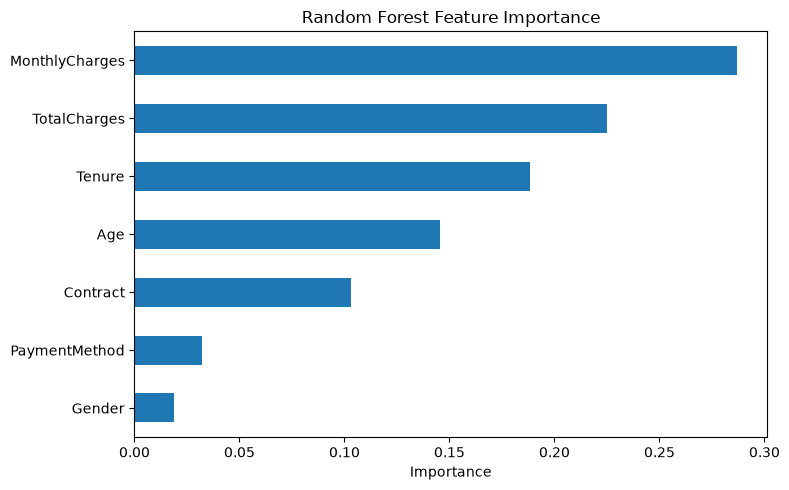

MonthlyCharges    0.2870
TotalCharges      0.2248
Tenure            0.1883
Age               0.1455
Contract          0.1031
PaymentMethod     0.0323
Gender            0.0189
dtype: float64

In [50]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind='barh')
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False).round(4)

In [51]:
# Logistic Regression coefficients (features are scaled, so sizes are comparable).
# Positive = pushes toward churn, negative = pushes toward staying.
coefs = pd.Series(log_model.coef_[0], index=X.columns).sort_values(ascending=False)
coefs.round(4)

MonthlyCharges    0.4999
TotalCharges      0.2721
PaymentMethod     0.0165
Gender            0.0146
Age              -0.0103
Tenure           -0.7085
Contract         -0.7928
dtype: float64

## 8. Conclusions

- Logistic regression reaches **72.68%** accuracy, only about 5.5 points above the majority-class baseline (about 66.9%). Accuracy alone overstates the model here because roughly one customer in three churns.
- On the churn class, precision is about 61% and recall about 45% (from the confusion matrix), so the model misses more than half of churners.

- **Model performance:** Random Forest beats Logistic Regression, with 73.7% vs 72.7% accuracy and 50.2% vs 44.8% churn recall. Both are only modestly above the 66.9% majority-class baseline, and both still miss about half of the customers who actually churn.
- **Top churn drivers:** Random Forest ranks `MonthlyCharges`, `TotalCharges` and `Tenure` highest. Logistic Regression shows longer `Contract` and longer `Tenure` lower churn, while higher `MonthlyCharges` raises it. `TotalCharges` largely reflects tenure times monthly charge, so it adds little on its own.
- **Business action 1:** move month-to-month customers onto one- or two-year contracts with discounts or incentives.
- **Business action 2:** run retention offers for new customers (early tenure) and review pricing for customers with high monthly charges.
- **Limitations:** the data is synthetic, categoricals are label-encoded, and there is no hyperparameter tuning or cross-validation yet.